<a href="https://colab.research.google.com/github/AmirthaaR/Customer-Churn-Analysis-and-Prediction/blob/main/Customer_Churn_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Saving Telco-Customer-Churn.csv to Telco-Customer-Churn.csv
Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset inspection

In [2]:
# Dataset information
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Statistical summary
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [3]:
# Check target distribution
print(df['Churn'].value_counts())

print("\nChurn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


Inspect data quality

In [4]:
print("DATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nSTATISTICAL SUMMARY")
display(df.describe())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Clean the data

In [5]:
# Convert TotalCharges into numeric format
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# Check missing values after conversion
print("Missing TotalCharges:", df['TotalCharges'].isnull().sum())

# Check rows containing missing TotalCharges
display(df[df['TotalCharges'].isnull()])

Missing TotalCharges: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [6]:
# Fill missing TotalCharges with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Remove customerID because it is only an identifier
df = df.drop('customerID', axis=1)

print("Updated Dataset Shape:", df.shape)
print("\nUpdated Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum().sum())

Updated Dataset Shape: (7043, 20)

Updated Data Types:
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

Missing Values:
0


Exploratory Data Analysis (EDA)

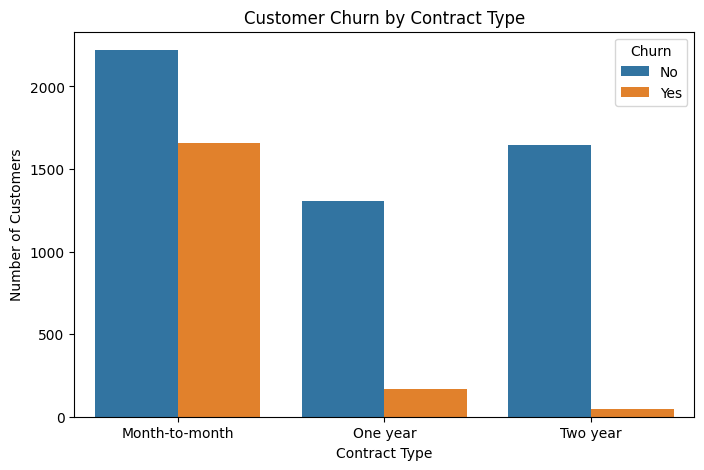

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Contract', hue='Churn')

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()

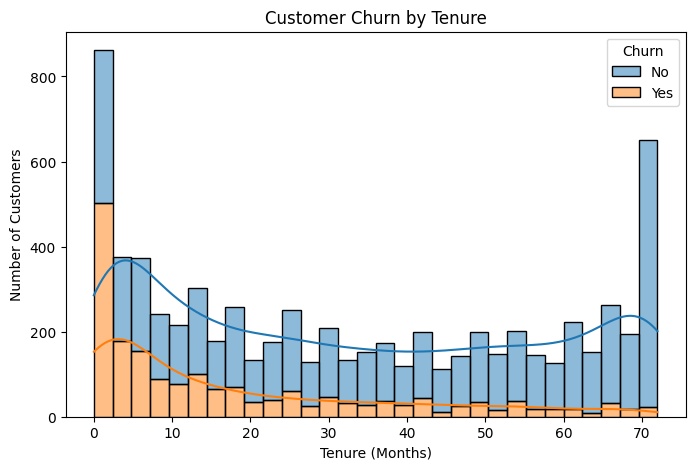

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='tenure', hue='Churn',
             bins=30, kde=True, multiple='stack')

plt.title('Customer Churn by Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.show()

Explore other churn patterns

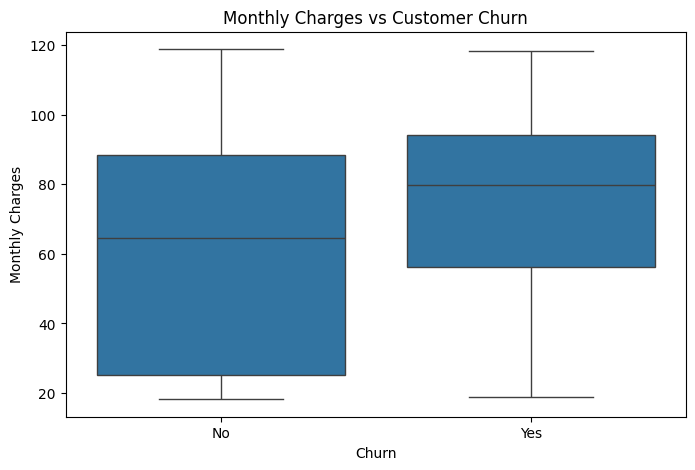

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Churn', y='MonthlyCharges')

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()

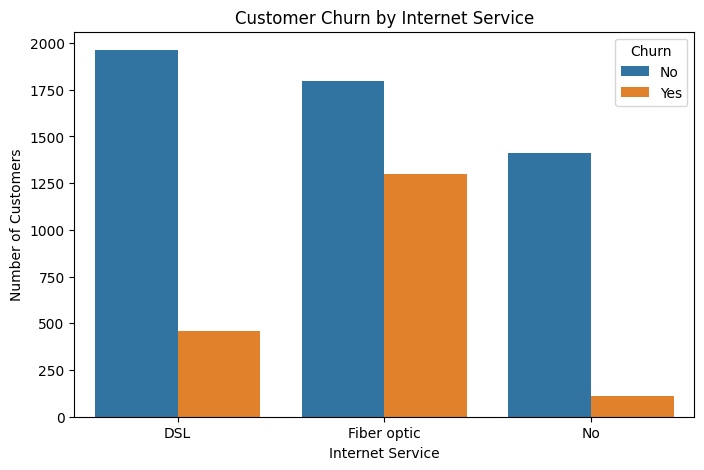

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='InternetService', hue='Churn')

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')
plt.show()

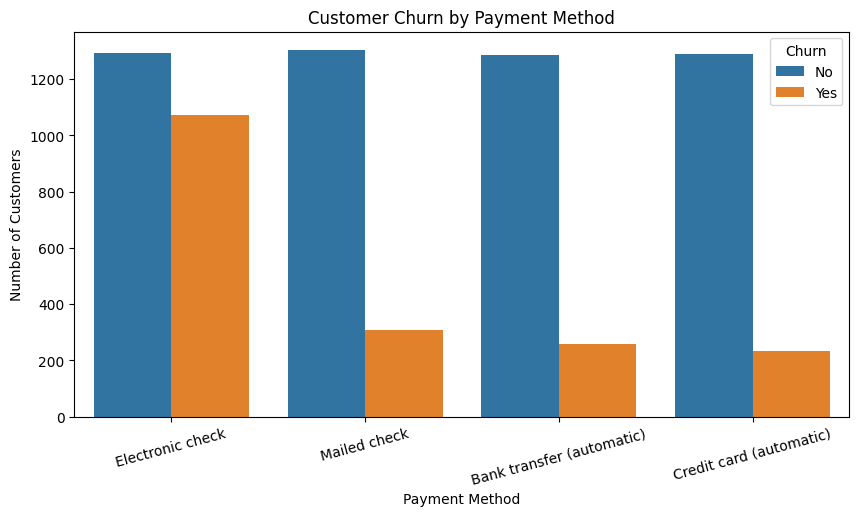

In [11]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='PaymentMethod', hue='Churn')

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')
plt.xticks(rotation=15)
plt.show()

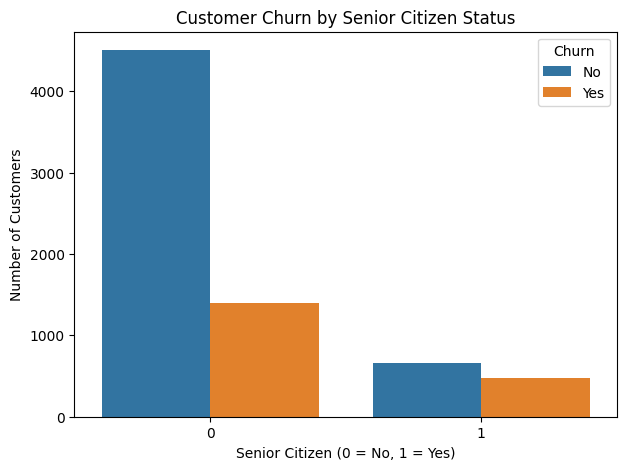

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='SeniorCitizen', hue='Churn')

plt.title('Customer Churn by Senior Citizen Status')
plt.xlabel('Senior Citizen (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')
plt.show()

Data Preprocessing

In [13]:
# Separate features and target
X = df.drop('Churn', axis=1)
y = df['Churn'].map({'Yes': 1, 'No': 0})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [14]:
# Identify numerical and categorical columns
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nNumber of Numerical Features:", len(numerical_features))

print("\nCategorical Features:", categorical_features)
print("\nNumber of Categorical Features:", len(categorical_features))

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Number of Numerical Features: 4

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of Categorical Features: 15


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training data: (5634, 19)
Testing data: (1409, 19)

Training target distribution:
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64


Model training

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import pandas as pd

In [18]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

print("Three models created successfully!")

Three models created successfully!


In [20]:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predictions
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Evaluation
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = pipeline

# Display comparison
results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8416
1,Random Forest,0.7828,0.6189,0.4733,0.5364,0.8232
2,Gradient Boosting,0.8027,0.6655,0.5160,0.5813,0.8434


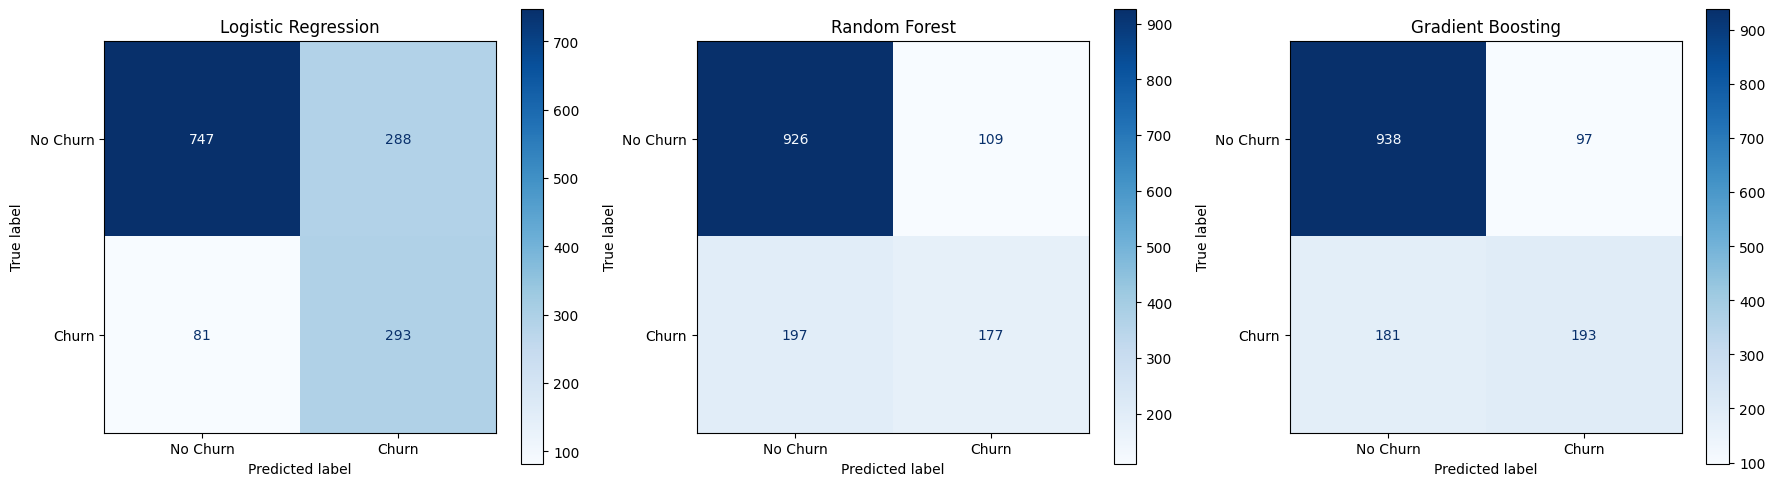

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pipeline) in zip(axes, trained_models.items()):

    y_pred = pipeline.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=['No Churn', 'Churn'],
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [22]:
for name, pipeline in trained_models.items():

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    y_pred = pipeline.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        target_names=['No Churn', 'Churn']
    ))


Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Random Forest
              precision    recall  f1-score   support

    No Churn       0.82      0.89      0.86      1035
       Churn       0.62      0.47      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409


Gradient Boosting
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       

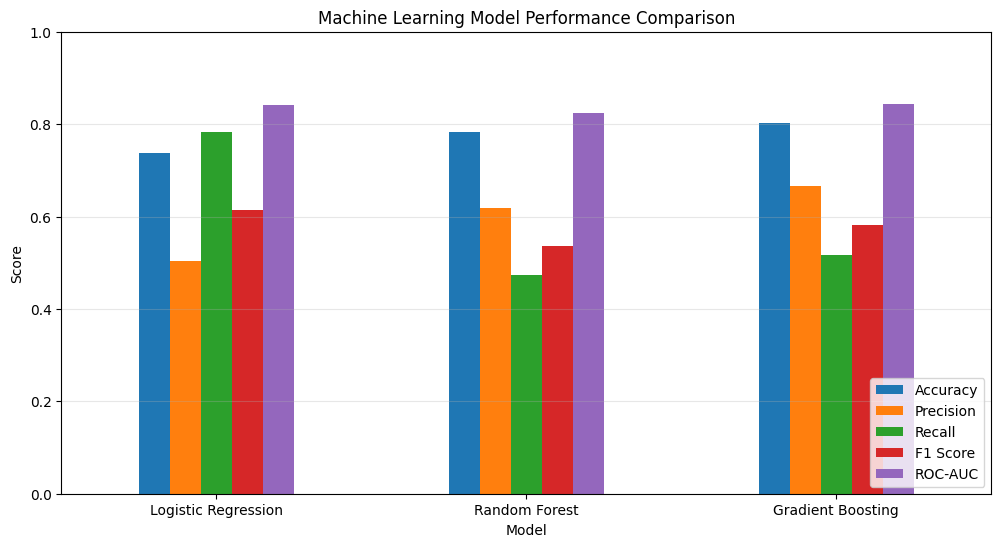

In [23]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']

results_df.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Machine Learning Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.show()

Improve model performance using threshold tuning

In [24]:
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training records:", X_train_new.shape[0])
print("Validation records:", X_val.shape[0])

Training records: 4507
Validation records: 1127


In [25]:
validation_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train_new, y_train_new)

    validation_models[name] = pipeline

print("All models trained on training subset!")

All models trained on training subset!


In [26]:
threshold_results = []

for name, pipeline in validation_models.items():

    y_prob = pipeline.predict_proba(X_val)[:, 1]

    best_threshold = 0
    best_f1 = 0

    for threshold in np.arange(0.20, 0.81, 0.01):

        y_pred = (y_prob >= threshold).astype(int)

        current_f1 = f1_score(y_val, y_pred)

        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = threshold

    y_pred = (y_prob >= best_threshold).astype(int)

    threshold_results.append({
        'Model': name,
        'Best Threshold': round(best_threshold, 2),
        'Precision': precision_score(y_val, y_pred),
        'Recall': recall_score(y_val, y_pred),
        'F1 Score': best_f1
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Model,Best Threshold,Precision,Recall,F1 Score
0,Logistic Regression,0.62,0.5977,0.6957,0.6430
1,Random Forest,0.34,0.5587,0.6689,0.6088
2,Gradient Boosting,0.37,0.6202,0.6990,0.6572


Final model training and testing

In [27]:
from sklearn.base import clone

final_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    final_models[name] = pipeline

print("All three final models trained successfully!")

All three final models trained successfully!


In [28]:
final_results = []

best_thresholds = {
    'Logistic Regression': 0.62,
    'Random Forest': 0.34,
    'Gradient Boosting': 0.37
}

for name, pipeline in final_models.items():

    threshold = best_thresholds[name]

    y_prob = pipeline.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= threshold).astype(int)

    final_results.append({
        'Model': name,
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

final_results_df = pd.DataFrame(final_results)

display(final_results_df.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.62,0.7686,0.5511,0.6925,0.6137,0.8416
1,Random Forest,0.34,0.7651,0.5475,0.6631,0.5998,0.8232
2,Gradient Boosting,0.37,0.7828,0.5756,0.6925,0.6286,0.8434


In [29]:
for name, pipeline in final_models.items():

    threshold = best_thresholds[name]

    y_prob = pipeline.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= threshold).astype(int)

    print("\n", "=" * 50)
    print(name, "- Final Test Results")
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        target_names=['No Churn', 'Churn']
    ))


Logistic Regression - Final Test Results
              precision    recall  f1-score   support

    No Churn       0.88      0.80      0.83      1035
       Churn       0.55      0.69      0.61       374

    accuracy                           0.77      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.77      0.78      1409


Random Forest - Final Test Results
              precision    recall  f1-score   support

    No Churn       0.87      0.80      0.83      1035
       Churn       0.55      0.66      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409


Gradient Boosting - Final Test Results
              precision    recall  f1-score   support

    No Churn       0.88      0.82      0.85      1035
       Churn       0.58      0.69      0.63       374

    accuracy                           0.78      1409
   macro a

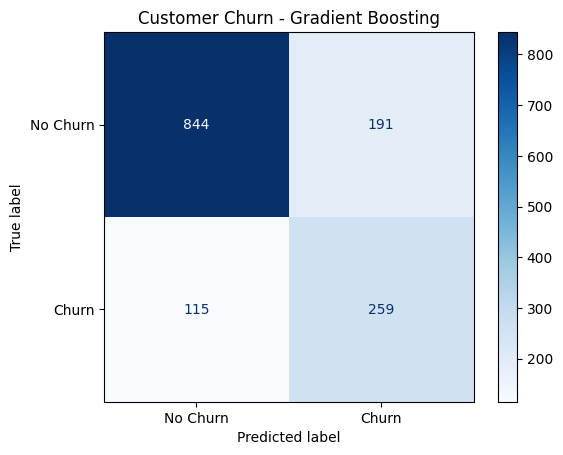

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_name = 'Gradient Boosting'
best_threshold = 0.37

best_model = final_models[best_name]

y_prob = best_model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= best_threshold).astype(int)

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn', 'Churn']
)

display.plot(cmap='Blues', values_format='d')
plt.title('Customer Churn - Gradient Boosting')
plt.show()

Build a customer churn prediction function

In [35]:
def predict_customer_churn(customer_data):

    input_df = pd.DataFrame([customer_data])

    probability = best_model.predict_proba(input_df)[0][1]

    prediction = (
        "Likely to Churn"
        if probability >= best_threshold
        else "Likely to Stay"
    )

    return {
        "Prediction": prediction,
        "Churn Probability": float(round(probability * 100, 2))
    }

In [36]:
import joblib

model_bundle = {
    'model': best_model,
    'threshold': best_threshold,
    'model_name': best_name
}

joblib.dump(model_bundle, 'customer_churn_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [37]:
loaded_bundle = joblib.load('customer_churn_model.pkl')

loaded_model = loaded_bundle['model']
loaded_threshold = loaded_bundle['threshold']

print("Model:", loaded_bundle['model_name'])
print("Threshold:", loaded_threshold)
print("Model loaded successfully!")

Model: Gradient Boosting
Threshold: 0.37
Model loaded successfully!


Create an interactive prediction interface

In [38]:
!pip install gradio

Create the Gradio prediction function

In [39]:
import gradio as gr
import pandas as pd

def churn_prediction(
    gender, senior_citizen, partner, dependents, tenure,
    phone_service, multiple_lines, internet_service,
    online_security, online_backup, device_protection,
    tech_support, streaming_tv, streaming_movies,
    contract, paperless_billing, payment_method,
    monthly_charges, total_charges
):

    customer = {
        'gender': gender,
        'SeniorCitizen': senior_citizen,
        'Partner': partner,
        'Dependents': dependents,
        'tenure': tenure,
        'PhoneService': phone_service,
        'MultipleLines': multiple_lines,
        'InternetService': internet_service,
        'OnlineSecurity': online_security,
        'OnlineBackup': online_backup,
        'DeviceProtection': device_protection,
        'TechSupport': tech_support,
        'StreamingTV': streaming_tv,
        'StreamingMovies': streaming_movies,
        'Contract': contract,
        'PaperlessBilling': paperless_billing,
        'PaymentMethod': payment_method,
        'MonthlyCharges': monthly_charges,
        'TotalCharges': total_charges
    }

    input_df = pd.DataFrame([customer])

    probability = loaded_model.predict_proba(input_df)[0][1]

    if probability >= loaded_threshold:
        prediction = "⚠️ Likely to Churn"
    else:
        prediction = "✅ Likely to Stay"

    return prediction, f"{probability * 100:.2f}%"

Create the interface

In [40]:
with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown("# Customer Churn Prediction")
    gr.Markdown("Enter customer details to estimate their likelihood of leaving the telecom service.")

    with gr.Row():
        with gr.Column():
            gender = gr.Dropdown(["Female", "Male"], label="Gender", value="Female")
            senior_citizen = gr.Dropdown([0, 1], label="Senior Citizen", value=0)
            partner = gr.Dropdown(["Yes", "No"], label="Partner", value="Yes")
            dependents = gr.Dropdown(["Yes", "No"], label="Dependents", value="No")
            tenure = gr.Slider(0, 72, value=5, step=1, label="Tenure (Months)")
            phone_service = gr.Dropdown(["Yes", "No"], label="Phone Service", value="Yes")
            multiple_lines = gr.Dropdown(["Yes", "No", "No phone service"], label="Multiple Lines", value="No")

        with gr.Column():
            internet_service = gr.Dropdown(["DSL", "Fiber optic", "No"], label="Internet Service", value="Fiber optic")
            online_security = gr.Dropdown(["Yes", "No", "No internet service"], label="Online Security", value="No")
            online_backup = gr.Dropdown(["Yes", "No", "No internet service"], label="Online Backup", value="No")
            device_protection = gr.Dropdown(["Yes", "No", "No internet service"], label="Device Protection", value="No")
            tech_support = gr.Dropdown(["Yes", "No", "No internet service"], label="Tech Support", value="No")
            streaming_tv = gr.Dropdown(["Yes", "No", "No internet service"], label="Streaming TV", value="Yes")
            streaming_movies = gr.Dropdown(["Yes", "No", "No internet service"], label="Streaming Movies", value="Yes")

    with gr.Row():
        with gr.Column():
            contract = gr.Dropdown(["Month-to-month", "One year", "Two year"], label="Contract", value="Month-to-month")
            paperless_billing = gr.Dropdown(["Yes", "No"], label="Paperless Billing", value="Yes")
            payment_method = gr.Dropdown(
                ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"],
                label="Payment Method",
                value="Electronic check"
            )

        with gr.Column():
            monthly_charges = gr.Number(label="Monthly Charges", value=85.50)
            total_charges = gr.Number(label="Total Charges", value=427.50)

    predict_button = gr.Button("Predict Churn", variant="primary")

    prediction_output = gr.Textbox(label="Prediction")
    probability_output = gr.Textbox(label="Churn Probability")

    predict_button.click(
        fn=churn_prediction,
        inputs=[
            gender, senior_citizen, partner, dependents, tenure,
            phone_service, multiple_lines, internet_service,
            online_security, online_backup, device_protection,
            tech_support, streaming_tv, streaming_movies,
            contract, paperless_billing, payment_method,
            monthly_charges, total_charges
        ],
        outputs=[prediction_output, probability_output]
    )

demo.launch(share=True)

/tmp/ipykernel_1100/637069152.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8f2e9e093aa8181171.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
